# 05 · Tertiary lymphoid structures (TLS)

Tertiary lymphoid structures are organised lymphoid aggregates that form in tumours under chronic inflammation. OpenTME detects them on the H&E slide and separates **immature** TLS (lymphoid aggregates) from **mature** TLS (with a germinal centre, where B cells are selected and become antibody-producing plasma cells). Each tumour is assigned to one of three classes: **no TLS**, **immature only**, or **mature** (at least one mature TLS).

As in notebook 04, **the image defines the groups and the molecular data explain them**:

1. **How common are TLS?** Distribution of the three classes in cold and hot tumours.
2. **ssGSEA, explained** with the TLS chemokine signatures as the example, including the real running-sum curve of two tumours.
3. **Do image TLS match their RNA footprint?** TLS signatures by class.
4. **What changes molecularly as TLS form and mature?** Two stepwise comparisons, first as an unbiased volcano screen and then as forest plots of the top hits:
   - **Formation:** immature only vs no TLS.
   - **Maturation:** mature vs immature only.
5. **TLS and the spatial phenotype:** are TLS different between inflamed and excluded tumours, and are the phenotype results robust to them?

**Cohort and model.** The formation and maturation comparisons use all tumours, because the "no TLS" class is very small among hot tumours. Since TLS are more frequent in tumours with more immune infiltrate, models adjust for subtype, purity **and leukocyte fraction**: the question becomes "at the same amount of immune infiltrate, what do TLS add?". As TLS also attract immune cells, adjusting for leukocyte fraction can remove part of their real effect, so the forest plots also show the model without it.

Parameters are in `configs/analysis.yaml` (section `tls_analysis`, plus the thresholds of `immune_phenotypes`); the models are those of notebook 04 (`src/opentme_tcga/stats.py`). The *Observations* describe the results of the pilot indication (breast cancer).

**Outputs**: tables in `results/<indication>/05_tls/` and figures in `figures/<indication>/05_tls/`.

## 0. Setup

In [1]:
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D
from statsmodels.stats.multitest import multipletests

from opentme_tcga import phenotypes as ph
from opentme_tcga import stats
from opentme_tcga.config import ensure_dirs, load_config
from opentme_tcga.plotting import PHENOTYPE_COLORS, TLS_GROUP_COLORS
from opentme_tcga.stats import add_fdr, zscore
from opentme_tcga.stats import assign_family
from opentme_tcga.tcga import load_labels, make_label, ssgsea_running_sum

INDICATION = "breast"          # name of a file in configs/indications/

cfg = load_config(INDICATION)
P = cfg["paths"]
TA, IP = cfg["tls_analysis"], cfg["immune_phenotypes"]
SUB = cfg["tcga_molecular"]["subtypes"]

OUT_DIR = P["results"] / "05_tls"
FIGS = P["figures"] / "05_tls"
ensure_dirs(cfg)
FIGS.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Configuration

Column names and settings come from the configuration; here they only get short names. The models are those of notebook 04, with the exposure set to the TLS step being compared.

In [2]:
IMG = TA["image"]
TLS_MATURE, TLS_IMMATURE = IMG["density_mature"], IMG["density_immature"]
TLS_PRESENT, TLS_MATURE_PRESENT = IMG["present"], IMG["mature_present"]
TLS_SIGNATURES = TA["signatures"]

SUBTYPE, SUBTYPE_LABEL = SUB["column"], SUB["label"]
PURITY, LF = IP["molecular"]["purity"], IP["molecular"]["leukocyte_fraction"]
MIN_PER_GROUP, MIN_SUBTYPE_LEVEL, FDR_ALPHA = IP["min_per_group"], IP["min_subtype_level"], IP["fdr_alpha"]
MIN_NON_MISSING, N_FOREST = TA["min_values"], TA["n_forest"]

TLS_GROUPS = ph.TLS_CLASSES
CONTRASTS = [tuple(c) for c in TA["contrasts"]]           # (name, reference class, comparison class)

# Adjustment sets; the main model adds leukocyte fraction
BASE_SPEC = f"{SUBTYPE_LABEL} + purity"
MAIN_SPEC = "+ leukocyte fraction (main)" if TA["adjust_for_leukocyte_fraction"] else BASE_SPEC
SPECS = {BASE_SPEC: {"categorical": [SUBTYPE], "continuous": [PURITY]}}
if TA["adjust_for_leukocyte_fraction"]:
    SPECS[MAIN_SPEC] = {"categorical": [SUBTYPE], "continuous": [PURITY, LF]}

LABELS = load_labels(P["configs"] / "variable_labels.yaml")
pretty_label = lambda col: make_label(col, LABELS) or col
fit_effect = partial(stats.fit_effect, min_per_group=MIN_PER_GROUP)
fit_logit = partial(stats.fit_logit, min_level=MIN_SUBTYPE_LEVEL)

## 2. Cohort: TLS classes, cold/hot and spatial phenotype

The TLS class comes from the presence flags of notebook 01; cold/hot and the spatial phenotype come from the table exported by notebook 04, so both notebooks use exactly the same definition.

In [3]:
df = pd.read_parquet(P["integrated"])
df["tls_group"] = ph.tls_class(df[TLS_PRESENT], df[TLS_MATURE_PRESENT])
df["tls_density_total"] = df[TLS_MATURE] + df[TLS_IMMATURE]

if not P["spatial_phenotypes"].exists():
    raise FileNotFoundError(f"{P['spatial_phenotypes'].name} not found: run notebook 04 first.")
phen = pd.read_parquet(P["spatial_phenotypes"], columns=["patient", "is_hot", "spatial_index_wtr", "spatial_phenotype"])
df = df.merge(phen, on="patient", how="left", validate="one_to_one")

df["immune_status"] = df["is_hot"].map({1.0: "Hot", 0.0: "Cold"})
if "thor_tmb" in df.columns:
    df["thor_tmb_log1p"] = np.log1p(df["thor_tmb"].clip(lower=0))

print(f"Tumours: {len(df)} | with TLS class: {df['tls_group'].notna().sum()}")
display(pd.crosstab(df["tls_group"], df["immune_status"], margins=True).reindex(TLS_GROUPS + ["All"]))

Tumours: 1025 | with TLS class: 1025


immune_status,Cold,Hot,All
tls_group,,,
No TLS,121,45,166
Immature only,312,312,624
Mature,66,142,208
All,499,499,998


## 3. How common are TLS in cold and hot tumours?

Percentage of tumours in each TLS class, in cold and hot tumours. TLS counts depend on the tissue area, so classes are based on presence and comparisons of amount use densities (TLS per area).

tls_group,No TLS,Immature only,Mature
immune_status,,,
Cold,24.2,62.5,13.2
Hot,9.0,62.5,28.5


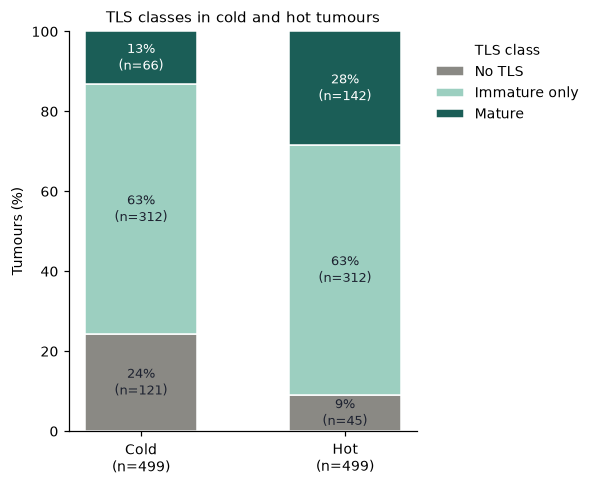

In [4]:
pct = (pd.crosstab(df["immune_status"], df["tls_group"], normalize="index") * 100).reindex(
    index=["Cold", "Hot"], columns=TLS_GROUPS)
counts = pd.crosstab(df["immune_status"], df["tls_group"]).reindex(index=["Cold", "Hot"], columns=TLS_GROUPS)
display(pct.round(1))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
bottom = np.zeros(len(pct))
for g in TLS_GROUPS:
    ax.bar(pct.index, pct[g], bottom=bottom, color=TLS_GROUP_COLORS[g], width=0.55, label=g, edgecolor="white")
    for i, (value, n) in enumerate(zip(pct[g], counts[g])):
        if value >= 5:
            ax.text(i, bottom[i] + value / 2, f"{value:.0f}%\n(n={n})", ha="center", va="center", fontsize=8.5,
                    color="white" if g == "Mature" else "#1d2230")
    bottom += pct[g].values
ax.set_xticks(range(len(pct)))
ax.set_xticklabels([f"{s}\n(n={counts.loc[s].sum()})" for s in pct.index])
ax.set_ylabel("Tumours (%)")
ax.set_ylim(0, 100)
ax.set_title("TLS classes in cold and hot tumours", fontsize=10)
ax.legend(title="TLS class", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(FIGS / "fig1_tls_classes_cold_hot.png", bbox_inches="tight")
plt.show()

## 4. ssGSEA, explained with the TLS signatures

The `sig_` columns are **ssGSEA** (single-sample gene set enrichment analysis) scores, computed in notebook 02:

1. **Rank the genes within one tumour.** All ~20,000 genes of that tumour are ordered from most to least expressed. Only the order is used, so the score is robust to technical differences between samples.
2. **Look at where the signature genes fall in that ranking.** In a tumour with mature TLS, CXCL13, CCL19 and CCL21 (the TLS-organiser signature) sit near the top of the ranking; in a tumour without TLS they are spread across it or near the bottom.
3. **Score how concentrated they are at the top.** A running sum walks down the ranking, going up at each signature gene and down at the others; the enrichment score summarises how far it climbs. One score per tumour and signature.
4. **Rescale across the cohort.** Each signature is median-centred and divided by its median absolute deviation (MAD), as in Bagaev et al. 2021. So 0 is the typical tumour of the cohort and +1 is one MAD above it (about 0.67 SD).

The two TLS signatures used here:
- **12-chemokine signature** (Coppola et al. 2011; Messina et al. 2012): CCL2, CCL3, CCL4, CCL5, CCL8, CCL18, CCL19, CCL21, CXCL9, CXCL10, CXCL11, CXCL13. It also captures interferon-driven inflammation (CXCL9–11).
- **TLS-organiser signature:** CXCL13, CCL19, CCL21, the chemokines that build the TLS structure.

The organiser genes are contained in the 12-chemokine signature, so the two scores are not independent evidence.

The figure below computes the ssGSEA running sum for real, from the expression matrix, for one representative tumour of the "No TLS" and "Mature" classes (the tumour whose 12-chemokine score is closest to its class median). A first check recomputes the enrichment score of every tumour: it should rank tumours in the same order as the `sig_tls_12_chemokines` column (Spearman close to 1), which confirms that the curve corresponds to the score used in the analyses.

Signature genes found in the matrix: 12/12
Spearman, recomputed ES vs sig_tls_12_chemokines: 1.000


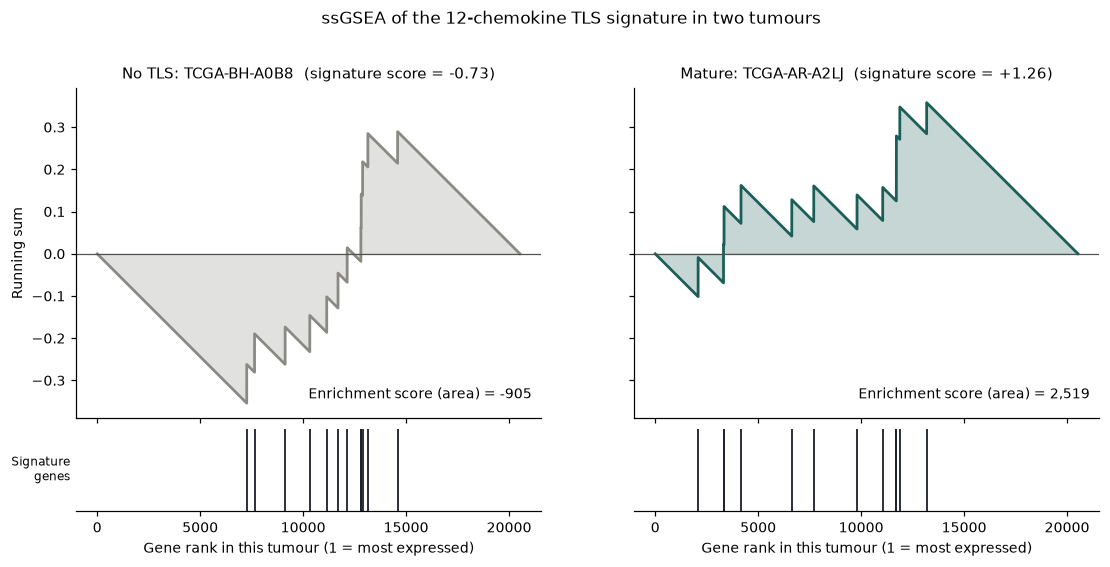

In [5]:
# ssGSEA running-sum plot, computed for real, for one representative tumour per TLS class
RS = TA["running_sum"]
SIGNATURE = f"sig_{RS['signature']}"
SIGNATURE_GENES = cfg["tcga_molecular"]["signatures"]["extra"][RS["signature"]]
EXAMPLE_CLASSES = RS["example_classes"]
ALPHA = RS["alpha"]  # gene weight exponent of ssGSEA (Barbie et al. 2009), the gseapy default

rna = pd.read_parquet(P["tcga_rna"])  # genes x patients, written by notebook 02
genes_in = [g for g in SIGNATURE_GENES if g in rna.index]
print(f"Signature genes found in the matrix: {len(genes_in)}/{len(SIGNATURE_GENES)}")


# Check against the scores in the table: the raw enrichment score of every tumour should rank
# tumours in the same order as the ssGSEA signature column (Spearman close to 1)
patients = [p for p in df["patient"] if p in rna.columns]
es_all = pd.Series({p: ssgsea_running_sum(rna[p], genes_in, ALPHA)[3] for p in patients})
check = df.set_index("patient").loc[patients, SIGNATURE]
print(f"Spearman, recomputed ES vs {SIGNATURE}: {es_all.corr(check, method='spearman'):.3f}")

# Representative tumour per class: the one whose signature score is closest to its class median
examples = {}
for g in EXAMPLE_CLASSES:
    sub = df[(df["tls_group"] == g) & df["patient"].isin(patients)].dropna(subset=[SIGNATURE])
    examples[g] = sub.loc[(sub[SIGNATURE] - sub[SIGNATURE].median()).abs().idxmin(), "patient"]

fig, axes = plt.subplots(2, len(EXAMPLE_CLASSES), figsize=(12, 5), sharex=True, sharey="row",
                         gridspec_kw={"height_ratios": [4, 1], "hspace": 0.05})
for j, g in enumerate(EXAMPLE_CLASSES):
    order, hits, running, es = ssgsea_running_sum(rna[examples[g]], genes_in, ALPHA)
    x = np.arange(1, len(order) + 1)
    color = TLS_GROUP_COLORS[g]

    ax = axes[0, j]
    ax.plot(x, running, color=color, lw=1.8)
    ax.fill_between(x, running, 0, color=color, alpha=0.25)
    ax.axhline(0, color="#52514e", lw=0.8)
    score = df.loc[df["patient"] == examples[g], SIGNATURE].iloc[0]
    ax.set_title(f"{g}: {examples[g]}  (signature score = {score:+.2f})", fontsize=10)
    ax.text(0.98, 0.05, f"Enrichment score (area) = {es:,.0f}", transform=ax.transAxes, ha="right", va="bottom",
        fontsize=9)
    if j == 0:
        ax.set_ylabel("Running sum")

    ax = axes[1, j]
    positions = x[hits]
    ax.vlines(positions, 0, 1, color="#1d2230", lw=1.2)
    ax.set_ylabel("Signature\ngenes" if j == 0 else "", rotation=0, ha="right", va="center", fontsize=8)
    ax.set_yticks([])
    ax.set_ylim(0, 1)
    ax.set_xlabel("Gene rank in this tumour (1 = most expressed)")
    for side in ["left", "right", "top"]:
        ax.spines[side].set_visible(False)

fig.suptitle("ssGSEA of the 12-chemokine TLS signature in two tumours", fontsize=11, y=1.02)
fig.savefig(FIGS / "fig_ssgsea_running_sum_examples.png", bbox_inches="tight")
plt.show()

## 5. Do image TLS match their RNA footprint?

TLS signatures by class, in all tumours and without adjustment: this is a validation of the image TLS detection against an independent measurement (RNA), not a test of a hypothesis. Spearman correlations of each signature with immature and mature TLS density are shown in the titles.

sig_tls_12_chemokines: median by class {'No TLS': np.float64(-0.73), 'Immature only': np.float64(-0.08), 'Mature': np.float64(1.26)}
sig_tls_organizers: median by class {'No TLS': np.float64(-0.75), 'Immature only': np.float64(0.01), 'Mature': np.float64(0.86)}


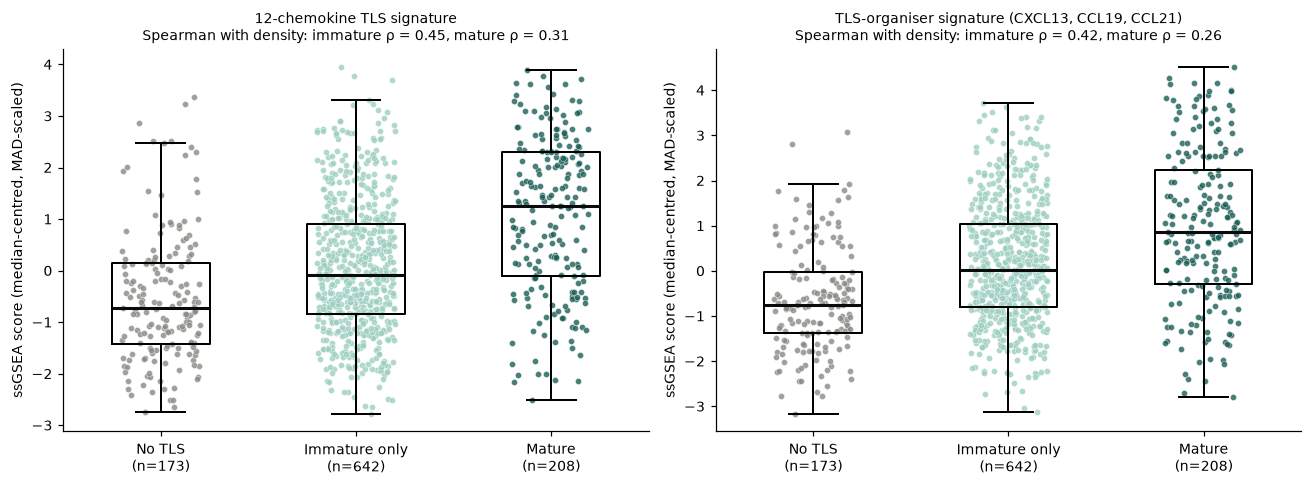

In [6]:
sigs = [s for s in TLS_SIGNATURES if s in df.columns]
fig, axes = plt.subplots(1, len(sigs), figsize=(6 * len(sigs), 4.5), squeeze=False)
for ax, sig in zip(axes[0], sigs):
    data = [df.loc[df["tls_group"] == g, sig].dropna() for g in TLS_GROUPS]
    ax.boxplot(data, positions=range(len(TLS_GROUPS)), widths=0.5, showfliers=False, zorder=3,
               medianprops={"color": "#0b0b0b", "lw": 2}, boxprops={"lw": 1.3}, whiskerprops={"lw": 1.3},
               capprops={"lw": 1.3})
    rng = np.random.default_rng(0)
    for i, (g, values) in enumerate(zip(TLS_GROUPS, data)):
        ax.scatter(i + rng.uniform(-0.2, 0.2, len(values)), values, s=16, alpha=0.8,
                   color=TLS_GROUP_COLORS[g], edgecolors="white", linewidths=0.3, zorder=2)
    rho_imm = df[TLS_IMMATURE].corr(df[sig], method="spearman")
    rho_mat = df[TLS_MATURE].corr(df[sig], method="spearman")
    ax.set_xticks(range(len(TLS_GROUPS)))
    ax.set_xticklabels([f"{g}\n(n={len(v)})" for g, v in zip(TLS_GROUPS, data)])
    ax.set_ylabel("ssGSEA score (median-centred, MAD-scaled)")
    ax.set_title(f"{TLS_SIGNATURES[sig]}\nSpearman with density: immature ρ = {rho_imm:.2f}, mature ρ = {rho_mat:.2f}",
                 fontsize=9)

    print(f"{sig}: median by class", {g: round(v.median(), 2) for g, v in zip(TLS_GROUPS, data)})
fig.tight_layout()
fig.savefig(FIGS / "fig2_tls_signatures_by_class.png", bbox_inches="tight")
plt.show()

**Observations (breast)**
- Both TLS signatures increase from no TLS to immature only to mature: the image detection agrees with an independent RNA measurement of the same structures.
- Agreement is moderate and the classes overlap: the H&E slide and the RNA come from different tissue pieces, and the signatures also capture inflammation outside TLS (e.g. CXCL9–11).
- The correlation with density is higher for immature than for mature TLS: mature TLS density is zero in most tumours, and the ties lower ρ.

## 6. What changes as TLS form and mature? Unbiased screen (volcano)

Two stepwise comparisons, each fitted only on the two classes involved:

- **Formation:** immature only (1) vs. no TLS (0).
- **Maturation:** mature (1) vs. immature only (0).

All molecular variables (prefixes `thor_`, `cib_`, `sig_`, `expr_`, `hyp_`, `mut_`, `path_`, `aneu_`, `abs_`) with at least `min_values` values (`tls_analysis` in the configuration) are tested, in all tumours, with the main model: `outcome ~ step + C(subtype) + purity + leukocyte fraction`.

- **Continuous variables:** standardised once across all tumours, OLS with HC3 SEs → difference in SD units. These are shown in the volcano plots.
- **Binary variables** (mutations, pathways, arm-level alterations): logistic regression → log2 odds ratio; mutations only in sequenced tumours. They are listed in a table below the figure.
- **FDR** (Benjamini-Hochberg) is computed within each comparison, across continuous and binary variables together.

Excluded from the screen: the covariates (purity, leukocyte fraction), the Saltz TIL fraction (derived from the H&E image, not molecular), the TLS signatures (already used as validation in section 5, and the RNA definition of the same structures), raw TMB (replaced by its log1p) and `mut_profiled`.

In [7]:
MOLECULAR_PREFIXES = tuple(IP["screen"]["prefixes"])
# Covariates, group-defining and redundant variables (notebook 04), TLS signatures and image-derived TILs
EXCLUDE = {PURITY, LF, *IP["screen"]["exclude"], *TLS_SIGNATURES, *TA["screen_exclude"]}

features = [c for c in df.columns
            if c.startswith(MOLECULAR_PREFIXES) and c not in EXCLUDE
            and pd.api.types.is_numeric_dtype(df[c]) and df[c].notna().sum() >= MIN_NON_MISSING]
binary_features = [c for c in features if set(df[c].dropna().unique()) <= {0, 1}]
continuous_features = [c for c in features if c not in binary_features and df[c].nunique() > 2]
print(f"Screen: {len(continuous_features)} continuous, {len(binary_features)} binary variables")

screen = df.copy()
for f in continuous_features:
    screen[f] = zscore(screen[f].astype(float))
profiled = screen["mut_profiled"] == 1 if "mut_profiled" in screen.columns else pd.Series(True, index=screen.index)


def contrast_data(data, reference, comparison):
    # Keep only the two classes of the step and code them 0 / 1
    d = data[data["tls_group"].isin([reference, comparison])].copy()
    d["step"] = (d["tls_group"] == comparison).astype(float)
    return d


rows = []
for name, ref, comp in CONTRASTS:
    d = contrast_data(screen, ref, comp)
    for spec, kwargs in SPECS.items():
        for f in continuous_features:
            rows.append({"contrast": name, "specification": spec, "feature": f, "type": "continuous",
                         **fit_effect(d, f, exposure="step", **kwargs)})
        for f in binary_features:
            data = d[profiled.loc[d.index]] if f.startswith("mut_") else d
            rows.append({"contrast": name, "specification": spec, "feature": f, "type": "binary",
                         **fit_logit(data, f, exposure="step", **kwargs)})

results = pd.DataFrame(rows)
results = add_fdr(results, by=["contrast", "specification"])
results["neg_log10_fdr"] = -np.log10(results["fdr"].clip(lower=1e-15))
results.to_csv(OUT_DIR / "tls_stepwise_screen.csv", index=False)

main = results[results["specification"] == MAIN_SPEC]
for name, _, _ in CONTRASTS:
    m = main[main["contrast"] == name]
    print(f"{name}: {(m['fdr'] < FDR_ALPHA).sum()} variables with FDR < {FDR_ALPHA} "
          f"(n = {int(m['n'].max())})")

Screen: 60 continuous, 26 binary variables
Formation: 7 variables with FDR < 0.05 (n = 753)
Maturation: 20 variables with FDR < 0.05 (n = 781)


In [8]:
SOURCE_NOTE = ("CIBERSORT: immune cell fraction among leukocytes (Thorsson et al. 2018); ssGSEA: gene-signature "
               "score; Thorsson: score from Thorsson et al. 2018.")
LABEL_FONTSIZE = 11
MAX_LABELS = TA["max_labels"]   # strongest hits labelled per volcano panel; the forest plot shows all

try:
    from adjustText import adjust_text  # pip install adjustText: moves labels so they do not overlap
except ImportError:
    adjust_text = None


def label_points(ax, d, n_top=0, max_labels=MAX_LABELS, x="effect", y="neg_log10_fdr"):
    # Label the strongest hits: significant points (plus the top n_top by p-value), at most max_labels per panel
    lab = d[(d["fdr"] < FDR_ALPHA) | d.index.isin(d.nsmallest(n_top, "p_value").index)].sort_values("p_value")
    if max_labels is not None:
        lab = lab.head(max_labels)
    x_span, y_span = np.diff(ax.get_xlim())[0], np.diff(ax.get_ylim())[0]
    # Points that (almost) coincide get their labels fanned out up and down, so they start apart
    cell = (lab[x] / (0.02 * x_span)).round().astype(int).astype(str) + "_" + \
           (lab[y] / (0.02 * y_span)).round().astype(int).astype(str)
    rank = lab.groupby(cell).cumcount()
    fan = rank.map(lambda k: 0 if k == 0 else (1 if k % 2 else -1) * ((k + 1) // 2))
    texts = []
    for (_, r), shift in zip(lab.iterrows(), fan):
        side = 1 if r[x] >= 0 else -1  # start each label on the outer side of its point
        texts.append(ax.text(r[x] + side * 0.03 * x_span, r[y] + shift * 0.06 * y_span, pretty_label(r["feature"]),
                             fontsize=LABEL_FONTSIZE, ha="left" if side > 0 else "right", va="center"))
    if adjust_text and texts:
        adjust_text(texts, x=d[x].values, y=d[y].values, target_x=lab[x].values, target_y=lab[y].values, ax=ax,
                    expand=(1.2, 1.6), force_text=(0.8, 1.2), force_static=(0.3, 0.5), force_pull=(0.01, 0.01),
                    max_move=(20, 20), time_lim=8,
                    arrowprops=dict(arrowstyle="-", color="#8a8984", lw=0.6))

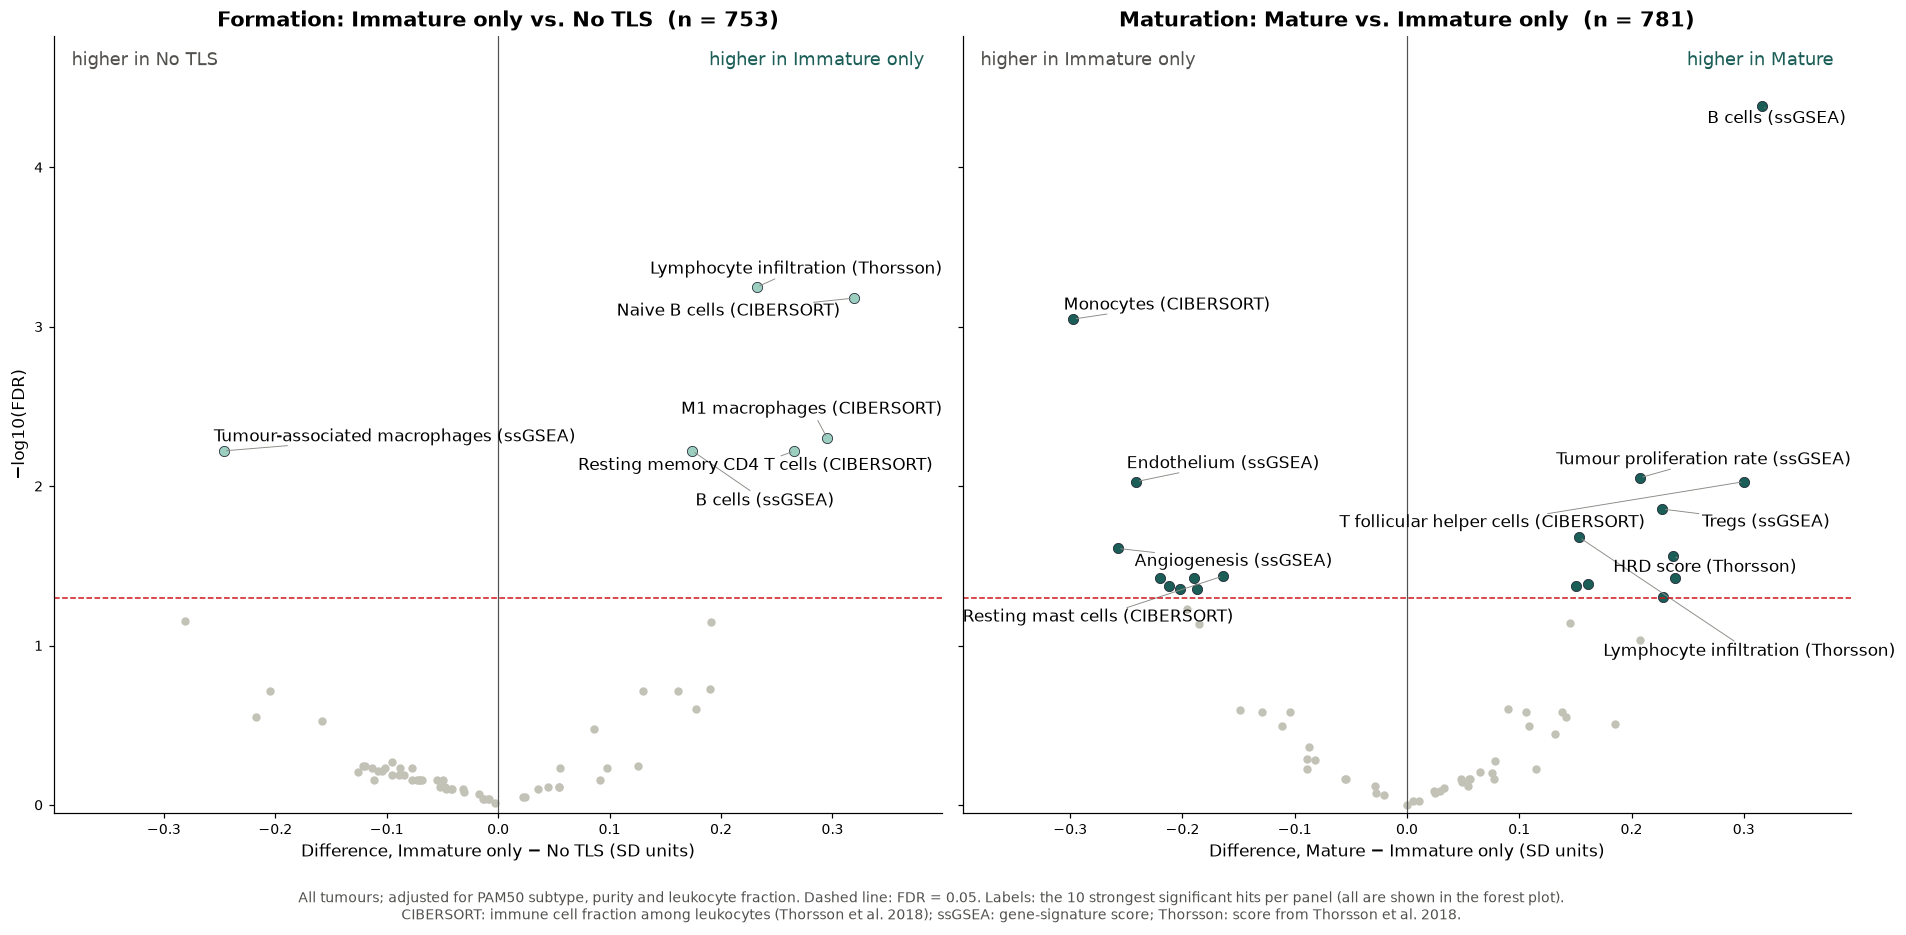

In [9]:
N_LABELS = 0          # extra labels beyond the significant ones
fig, axes = plt.subplots(1, len(CONTRASTS), figsize=(17, 8), sharey=True)
panels = []
cont_main = main[main["type"] == "continuous"].dropna(subset=["effect", "fdr"])
y_max = max(1.8, cont_main["neg_log10_fdr"].max() * 1.1)

for ax, (name, ref, comp) in zip(axes, CONTRASTS):
    d = cont_main[cont_main["contrast"] == name]
    hit = d["fdr"] < FDR_ALPHA
    ax.scatter(d.loc[~hit, "effect"], d.loc[~hit, "neg_log10_fdr"], s=30, color="#c3c2b7", linewidths=0)
    ax.scatter(d.loc[hit, "effect"], d.loc[hit, "neg_log10_fdr"], s=45, color=TLS_GROUP_COLORS[comp],
               edgecolors="#1d2230", linewidths=0.5)
    x_lim = max(0.3, d["effect"].abs().max() * 1.25)
    ax.set_xlim(-x_lim, x_lim)
    ax.set_ylim(-0.05, y_max)
    panels.append((ax, d))
    ax.axhline(-np.log10(FDR_ALPHA), color="#cb181d", ls="--", lw=1)
    ax.axvline(0, color="#525252", lw=0.8)
    ax.text(0.02, 0.98, f"higher in {ref}", transform=ax.transAxes, va="top", fontsize=11.5, color="#52514e")
    ax.text(0.98, 0.98, f"higher in {comp}", transform=ax.transAxes, va="top", ha="right", fontsize=11.5,
            color=TLS_GROUP_COLORS["Mature"])
    ax.set_xlabel(f"Difference, {comp} − {ref} (SD units)", fontsize=11)
    ax.set_title(f"{name}: {comp} vs. {ref}  (n = {int(d['n'].max())})", fontsize=14, fontweight="bold")
axes[0].set_ylabel("−log10(FDR)", fontsize=11)
fig.text(0.5, -0.05, f"All tumours; adjusted for {SUBTYPE_LABEL}, purity and leukocyte fraction. Dashed line: FDR = 0.05. "
         f"Labels: the {MAX_LABELS} strongest significant hits per panel (all are shown in the forest plot).\n"
         + SOURCE_NOTE, ha="center", fontsize=9, color="#52514e")
fig.tight_layout()
for ax, d in panels:  # place labels last, once the layout is final
    label_points(ax, d, N_LABELS)
fig.savefig(FIGS / "fig3_volcano_tls_formation_maturation.png", bbox_inches="tight")
plt.show()

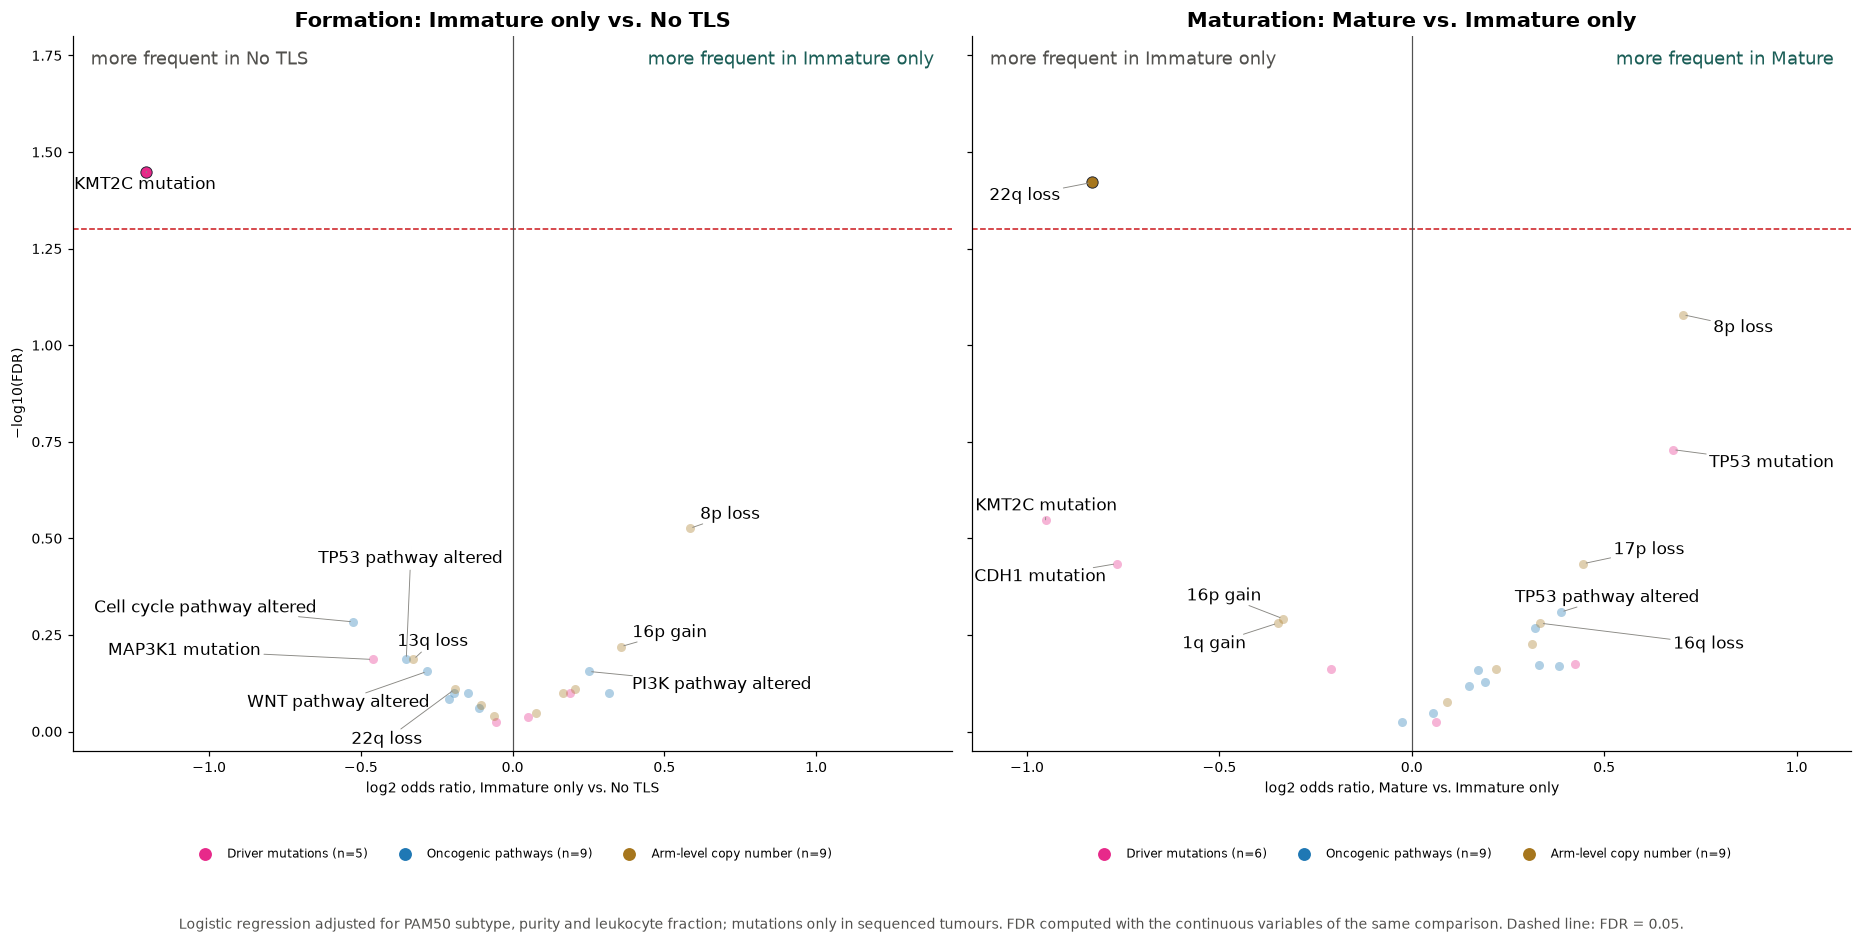

,contrast,feature,effect,ci_lower,ci_upper,p_value,fdr,n
150,Formation,mut_KMT2C,-1.207,-2.003,-0.410,0.003,0.036,692
341,Maturation,aneu_22q_loss,-0.832,-1.427,-0.236,0.006,0.038,642
338,Maturation,aneu_8p_loss,0.704,0.094,1.315,0.024,0.083,667
318,Maturation,mut_TP53,0.678,-0.022,1.379,0.058,0.186,720
166,Formation,aneu_8p_loss,0.584,-0.019,1.187,0.058,0.298,643
322,Maturation,mut_KMT2C,-0.952,-2.134,0.231,0.115,0.283,720
153,Formation,path_cell_cycle,-0.524,-1.184,0.135,0.119,0.520,541
337,Maturation,aneu_17p_loss,0.445,-0.196,1.087,0.174,0.368,676
321,Maturation,mut_CDH1,-0.767,-1.876,0.342,0.175,0.368,720
167,Formation,aneu_16p_gain,0.357,-0.211,0.924,0.218,0.603,679


In [10]:
# Volcano of binary variables (mutations, pathways, arm-level alterations), same models as the continuous volcano
BINARY_FAMILIES = {"mut_": ("Driver mutations", "#e7298a"), "path_": ("Oncogenic pathways", "#1f78b4"),
                   "aneu_": ("Arm-level copy number", "#a6761d")}
N_LABELS_BINARY = 10   # extra labels beyond the significant ones


def binary_family(feature):
    for prefix, (name, _) in BINARY_FAMILIES.items():
        if feature.startswith(prefix):
            return name
    return "Other"


family_colors = {name: color for name, color in BINARY_FAMILIES.values()} | {"Other": "#8c8c8c"}
bin_main = main[main["type"] == "binary"].dropna(subset=["effect", "fdr"]).copy()
bin_main["family"] = bin_main["feature"].map(binary_family)
y_max = max(1.8, bin_main["neg_log10_fdr"].max() * 1.15)

fig, axes = plt.subplots(1, len(CONTRASTS), figsize=(17, 8), sharey=True)
panels = []
for ax, (name, ref, comp) in zip(axes, CONTRASTS):
    d = bin_main[bin_main["contrast"] == name]
    for fam, color in family_colors.items():
        sub = d[d["family"] == fam]
        if sub.empty:
            continue
        hit = sub["fdr"] < FDR_ALPHA
        ax.scatter(sub.loc[~hit, "effect"], sub.loc[~hit, "neg_log10_fdr"], s=35, color=color, alpha=0.35,
                   linewidths=0)
        ax.scatter(sub.loc[hit, "effect"], sub.loc[hit, "neg_log10_fdr"], s=55, color=color,
                   edgecolors="#1d2230", linewidths=0.6)
        ax.scatter([], [], s=55, color=color, label=f"{fam} (n={len(sub)})")  # one legend entry per family
    x_lim = max(0.5, d["effect"].abs().max() * 1.2)
    ax.set_xlim(-x_lim, x_lim)
    ax.set_ylim(-0.05, y_max)
    panels.append((ax, d))
    ax.axhline(-np.log10(FDR_ALPHA), color="#cb181d", ls="--", lw=1)
    ax.axvline(0, color="#525252", lw=0.8)
    ax.text(0.02, 0.98, f"more frequent in {ref}", transform=ax.transAxes, va="top", fontsize=11.5, color="#52514e")
    ax.text(0.98, 0.98, f"more frequent in {comp}", transform=ax.transAxes, va="top", ha="right", fontsize=11.5,
            color=TLS_GROUP_COLORS["Mature"])
    ax.set_xlabel(f"log2 odds ratio, {comp} vs. {ref}")
    ax.set_title(f"{name}: {comp} vs. {ref}", fontsize=14, fontweight="bold")
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
axes[0].set_ylabel("−log10(FDR)")
fig.text(0.5, -0.06, f"Logistic regression adjusted for {SUBTYPE_LABEL}, purity and leukocyte fraction; mutations only in "
         "sequenced tumours. FDR computed with the continuous variables of the same comparison. Dashed line: FDR = 0.05.",
         ha="center", fontsize=9, color="#52514e")
fig.tight_layout()
for ax, d in panels:  # place labels last, once the layout is final
    label_points(ax, d, N_LABELS_BINARY)
fig.savefig(FIGS / "fig3b_volcano_tls_binary.png", bbox_inches="tight")
plt.show()

display(bin_main.sort_values("p_value")[["contrast", "feature", "effect", "ci_lower", "ci_upper", "p_value", "fdr", "n"]]
        .round(3).head(15))

In [11]:
# FDR among binary variables only, within each comparison
check = bin_main.copy()
for name in check["contrast"].unique():
    idx = check["contrast"] == name
    check.loc[idx, "fdr_binary_only"] = multipletests(check.loc[idx, "p_value"], method="fdr_bh")[1]
display(check.nsmallest(6, "p_value")[["contrast", "feature", "effect", "p_value", "fdr", "fdr_binary_only"]].round(3))

,contrast,feature,effect,p_value,fdr,fdr_binary_only
150,Formation,mut_KMT2C,-1.207,0.003,0.036,0.069
341,Maturation,aneu_22q_loss,-0.832,0.006,0.038,0.149
338,Maturation,aneu_8p_loss,0.704,0.024,0.083,0.286
318,Maturation,mut_TP53,0.678,0.058,0.186,0.461
166,Formation,aneu_8p_loss,0.584,0.058,0.298,0.664
322,Maturation,mut_KMT2C,-0.952,0.115,0.283,0.686


## 7. Top hits: forest plots of formation and maturation

The forest plots zoom in on the variables with the strongest evidence in the volcano: the top continuous variables by FDR in either comparison (main model). Each row shows both comparisons side by side, with the two adjustment sets:

- **Orange (circle):** adjusted for subtype + purity.
- **Blue (square), main model:** additionally adjusted for leukocyte fraction.

If an effect holds in blue, it is specific to TLS and not just a consequence of more immune infiltrate. If it is present in orange but disappears in blue, it mainly reflects the amount of infiltrate that comes with TLS. Filled markers: FDR < 0.05.

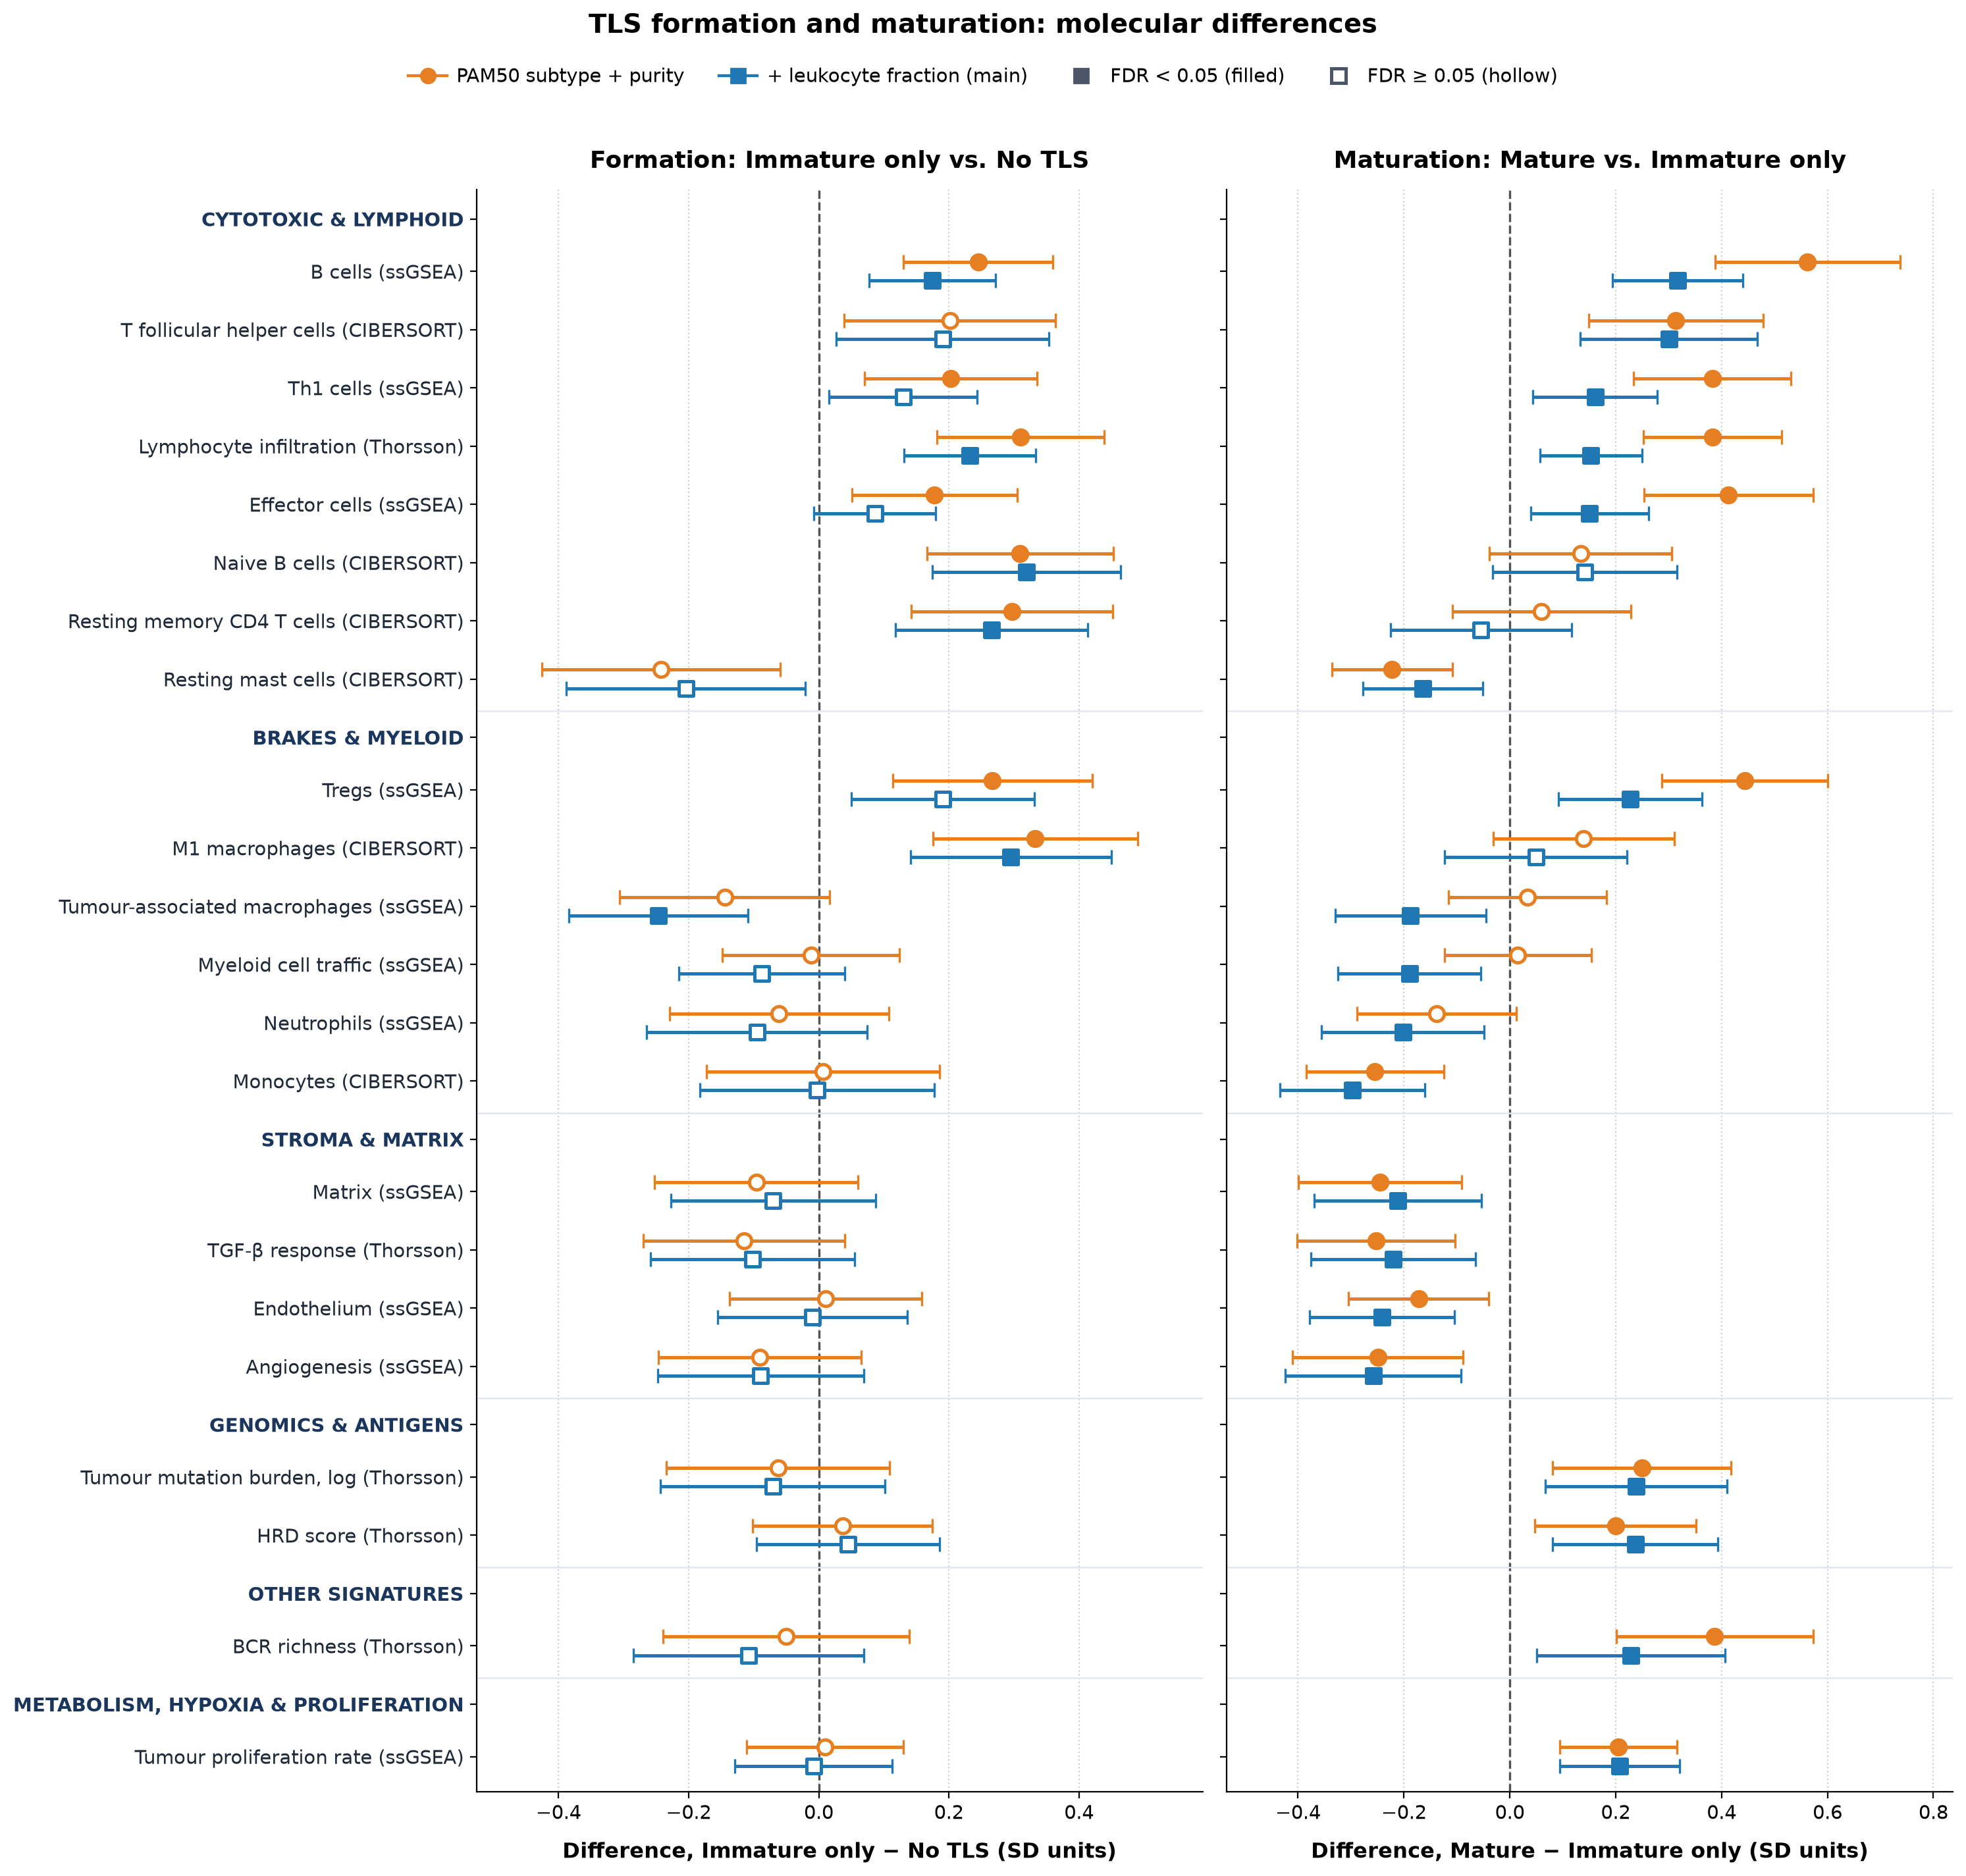

In [12]:
# Forest plot of every continuous variable significant (FDR < 0.05, main model) in either step,
# grouped by biological family; same style as the forest plot of notebook 04
significant = cont_main.loc[cont_main["fdr"] < FDR_ALPHA, "feature"].unique().tolist()
if not significant:  # fallback so the figure is never empty
    significant = cont_main.groupby("feature")["fdr"].min().nsmallest(N_FOREST).index.tolist()
maturation = (cont_main[(cont_main["contrast"] == CONTRASTS[-1][0]) & cont_main["feature"].isin(significant)]
              .set_index("feature")["effect"].reindex(significant).fillna(0))
families = pd.Series({f: assign_family(f) for f in significant})
forest = results[results["feature"].isin(significant) & (results["type"] == "continuous")]
forest.to_csv(OUT_DIR / "tls_forest_significant.csv", index=False)

# Layout: families from top to bottom (largest family first), variables ordered by the maturation effect
rows, headers, div_lines, y = [], [], [], 0.0
for fam in reversed(families.value_counts().index.tolist()):
    for feature in maturation[families == fam].sort_values().index:
        rows.append((y, feature))
        y += 1.0
    headers.append((y - 0.1, fam))
    div_lines.append(y + 0.35)
    y += 0.9
order = [f for _, f in rows]

STYLE = {BASE_SPEC: ("#e67e22", "o", 0.16), MAIN_SPEC: ("#1f77b4", "s", -0.16)}
fig, axes = plt.subplots(1, len(CONTRASTS), figsize=(15, 0.42 * (len(rows) + len(headers)) + 2.5), dpi=200,
                         sharey=True)
for ax, (name, ref, comp) in zip(axes, CONTRASTS):
    ax.axvline(0, color="#525252", linestyle="--", lw=1.2)
    for y_div in div_lines[:-1]:
        ax.axhline(y_div, color="#e2e8f0", lw=0.9)
    sub = forest[forest["contrast"] == name]
    for y_row, feature in rows:
        for spec, (color, marker, offset) in STYLE.items():
            r = sub[(sub["feature"] == feature) & (sub["specification"] == spec)]
            if r.empty or np.isnan(r["effect"].iloc[0]):
                continue
            r = r.iloc[0]
            ax.errorbar(r["effect"], y_row + offset, xerr=[[r["effect"] - r["ci_lower"]], [r["ci_upper"] - r["effect"]]],
                        fmt="none", ecolor=color, elinewidth=1.8, capsize=4, capthick=1.2)
            ax.scatter(r["effect"], y_row + offset, marker=marker, s=65, linewidths=1.8, zorder=4,
                       facecolors=color if r["fdr"] < FDR_ALPHA else "white", edgecolors=color)
    ci = sub[sub["feature"].isin(order)][["ci_lower", "ci_upper"]].stack()
    ax.set_xlim(min(ci.min(), 0) - 0.1, max(ci.max(), 0) + 0.1)
    ax.set_xlabel(f"Difference, {comp} − {ref} (SD units)", fontsize=11.5, fontweight="bold", labelpad=10)
    ax.set_title(f"{name}: {comp} vs. {ref}", fontsize=13, fontweight="bold", pad=12)
    ax.grid(axis="x", linestyle=":", alpha=0.6)
    ax.tick_params(axis="both", labelsize=10.5)

# Y axis: variables, with the family name as a bold header above each group
ticks = [y for y, _ in rows] + [y for y, _ in headers]
labels = [pretty_label(f) for _, f in rows] + [fam.upper() for _, fam in headers]
axes[0].set_yticks(ticks)
axes[0].set_yticklabels(labels, color="#1f2937")
for tick in axes[0].get_yticklabels()[len(rows):]:
    tick.set_fontweight("bold")
    tick.set_color("#1a365d")
axes[0].set_ylim(-0.6, y - 0.5)

fig.suptitle("TLS formation and maturation: molecular differences", fontsize=14.5, fontweight="bold", y=0.995)
fig.legend(handles=[
    Line2D([0], [0], marker="o", color=STYLE[BASE_SPEC][0], lw=1.6, markersize=8, label=BASE_SPEC),
    Line2D([0], [0], marker="s", color=STYLE[MAIN_SPEC][0], lw=1.6, markersize=8, label=MAIN_SPEC),
    Line2D([0], [0], marker="s", color="#4a5568", lw=0, markersize=8, label=f"FDR < {FDR_ALPHA} (filled)"),
    Line2D([0], [0], marker="s", color="#4a5568", lw=0, markerfacecolor="white", markeredgewidth=1.8, markersize=8,
           label=f"FDR ≥ {FDR_ALPHA} (hollow)"),
], loc="upper center", bbox_to_anchor=(0.5, 0.975), ncol=4, frameon=False, fontsize=10.5,
    handletextpad=0.5, columnspacing=1.8)
fig.tight_layout(rect=(0, 0, 1, 0.955))
fig.savefig(FIGS / "fig4_forest_tls_formation_maturation.png", bbox_inches="tight", dpi=300)
plt.show()

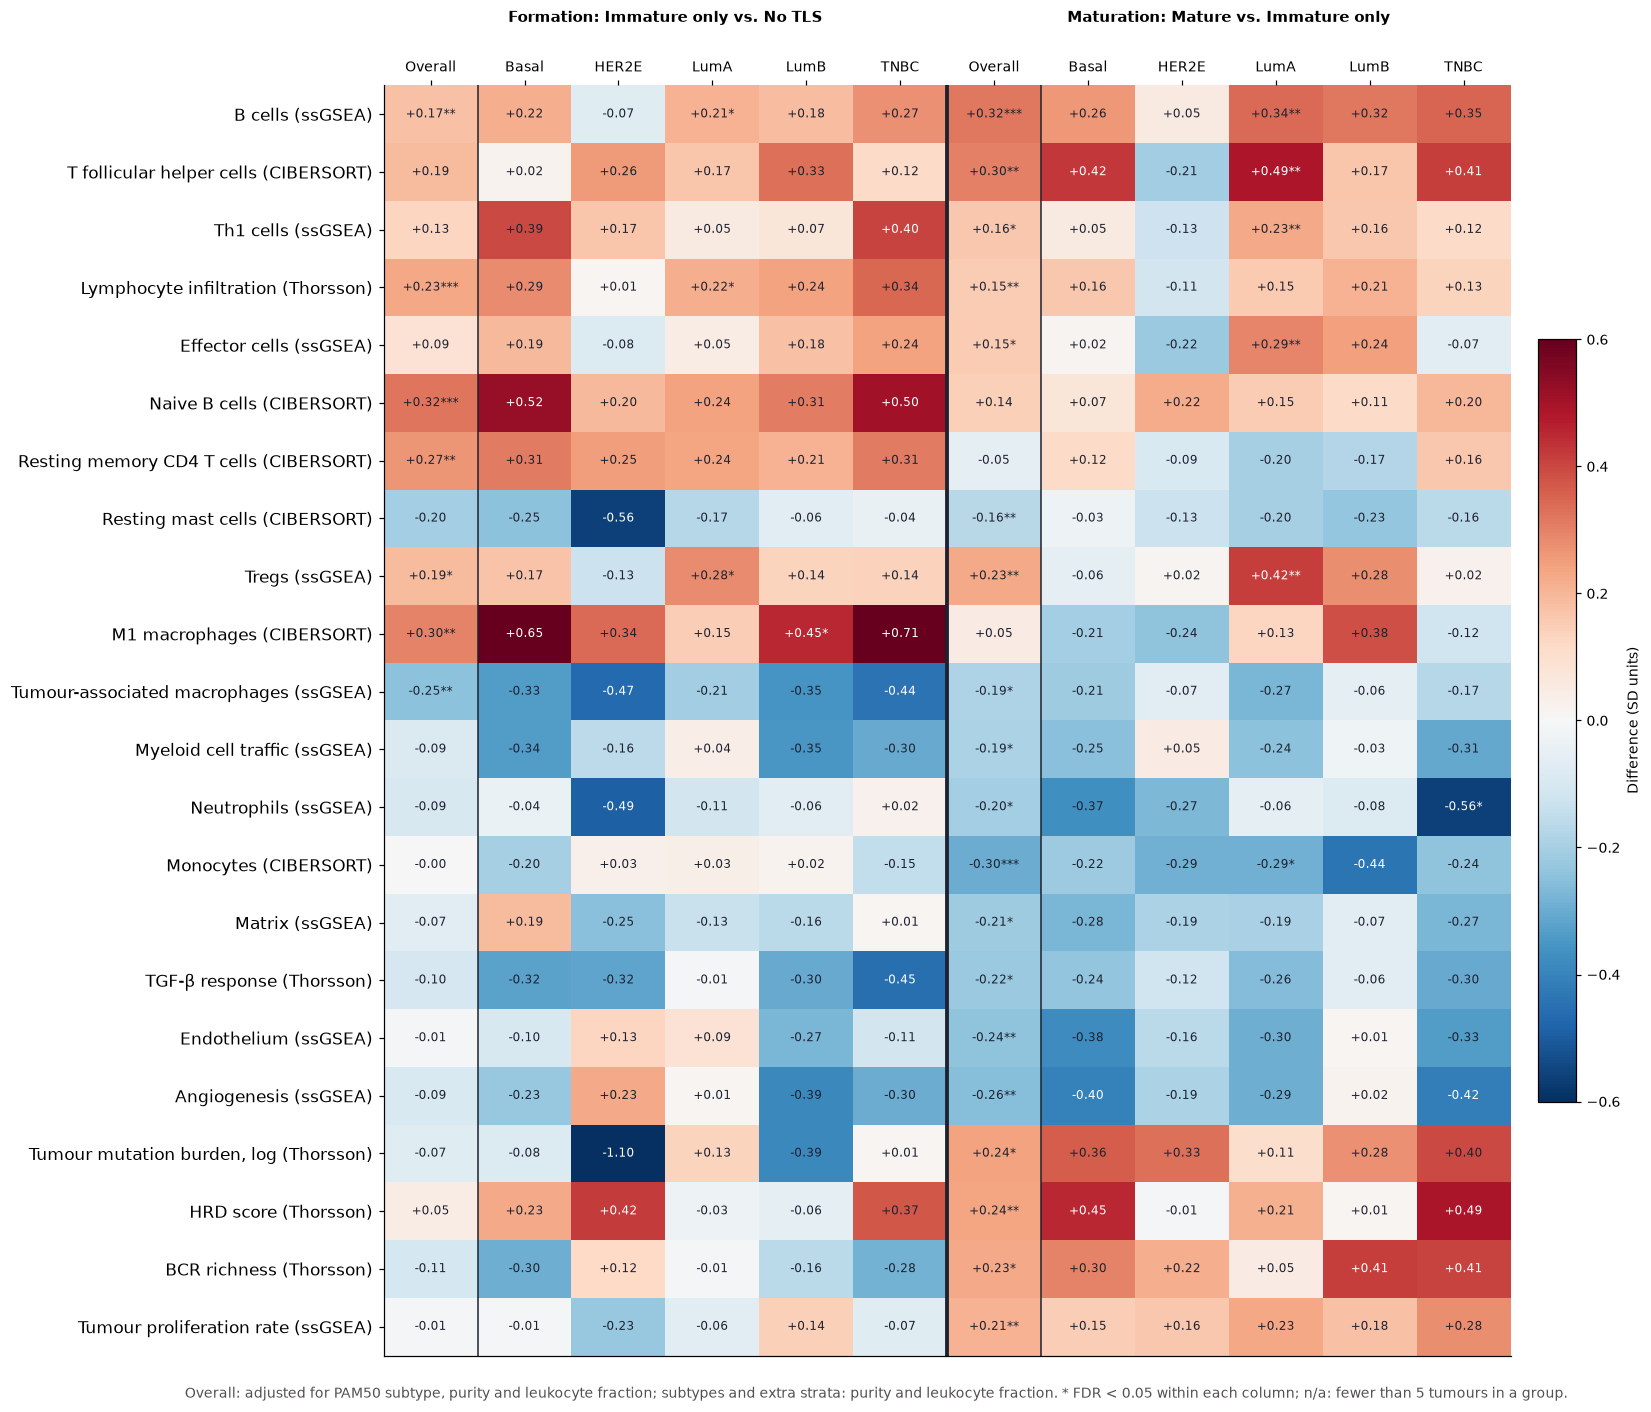

In [13]:
# Consistency across subtypes: the same two steps within each subtype and extra stratum (e.g. TNBC)
counts = screen[SUBTYPE].value_counts()
SUBTYPE_ORDER = SUB.get("order") or counts.index.tolist()
HEAT_SUBTYPES = [s for s in (IP["subtype_strata"] or SUBTYPE_ORDER) if counts.get(s, 0) >= IP["min_stratum_size"]]

strata = {"Overall": (screen, {"categorical": [SUBTYPE], "continuous": [PURITY, LF]})}
strata.update({s: (screen[screen[SUBTYPE] == s], {"continuous": [PURITY, LF]}) for s in HEAT_SUBTYPES})
for name, col in IP["extra_strata"].items():
    if col in screen.columns:
        strata[name] = (screen[screen[col] == 1], {"continuous": [PURITY, LF]})

heat = pd.DataFrame([
    {"contrast": name, "stratum": stratum, "feature": f,
     **fit_effect(contrast_data(data, ref, comp), f, exposure="step", **kwargs)}
    for name, ref, comp in CONTRASTS for stratum, (data, kwargs) in strata.items() for f in order
])
heat = add_fdr(heat, by=["contrast", "stratum"])
heat.to_csv(OUT_DIR / "tls_subtype_heatmap.csv", index=False)

# Columns: one block per step, strata within each block
columns = [(name, s) for name, _, _ in CONTRASTS for s in strata]
eff = heat.pivot_table(index="feature", columns=["contrast", "stratum"], values="effect").reindex(
    index=order[::-1], columns=columns)
fdr = heat.pivot_table(index="feature", columns=["contrast", "stratum"], values="fdr").reindex(
    index=order[::-1], columns=columns)

v = 0.6
fig, ax = plt.subplots(figsize=(1.0 * len(columns) + 4, 0.45 * len(order) + 2.5))
im = ax.imshow(eff.values, cmap="RdBu_r", vmin=-v, vmax=v, aspect="auto")
for i in range(eff.shape[0]):
    for j in range(eff.shape[1]):
        e, q = eff.iat[i, j], fdr.iat[i, j]
        if np.isnan(e):
            ax.text(j, i, "n/a", ha="center", va="center", fontsize=8, color="#8a8984")
            continue
        stars = "***" if q < 0.001 else "**" if q < 0.01 else "*" if q < FDR_ALPHA else ""
        ax.text(j, i, f"{e:+.2f}{stars}", ha="center", va="center", fontsize=8,
                color="white" if abs(e) > 0.4 else "#1d2230")
n_strata = len(strata)
for k in range(1, len(CONTRASTS)):
    ax.axvline(k * n_strata - 0.5, color="#1d2230", lw=2.5)
for k in range(len(CONTRASTS)):
    ax.axvline(k * n_strata + 0.5, color="#1d2230", lw=1)  # separates Overall from the subtypes
    name, ref, comp = CONTRASTS[k]
    ax.text(k * n_strata + (n_strata - 1) / 2, -1.6, f"{name}: {comp} vs. {ref}", ha="center", fontsize=10,
            fontweight="bold")
ax.set_xticks(range(len(columns)))
ax.set_xticklabels([s for _, s in columns], fontsize=9)
ax.xaxis.tick_top()
ax.set_yticks(range(len(eff.index)))
ax.set_yticklabels([pretty_label(f) for f in eff.index], fontsize=LABEL_FONTSIZE)
cbar = fig.colorbar(im, ax=ax, shrink=0.6, pad=0.02)
cbar.set_label("Difference (SD units)")
fig.text(0.5, -0.02, f"Overall: adjusted for {SUBTYPE_LABEL}, purity and leukocyte fraction; subtypes and extra strata: purity and "
         "leukocyte fraction. * FDR < 0.05 within each column; n/a: fewer than 5 tumours in a group.",
         ha="center", fontsize=9, color="#52514e")
fig.tight_layout()
fig.savefig(FIGS / "fig4b_heatmap_tls_subtypes.png", bbox_inches="tight")
plt.show()

## 8. TLS and the spatial phenotype

TLS usually form in the stroma and at the invasive margin, so they could raise the lymphocyte density at the margin and push tumours towards "excluded". Two checks, in hot tumours (where the phenotype is defined):

1. **Descriptive:** TLS classes by phenotype, and TLS density vs the infiltration index.
2. **Robustness of the phenotype results** (`robustness_outcomes` in the configuration; breast: COL10A1): `outcome ~ phenotype + subtype + purity`, refitted after adding mature TLS presence and immature TLS density as covariates.

TLS class by phenotype, hot tumours (row %):


tls_group,No TLS,Immature only,Mature
spatial_phenotype,,,
Excluded,6.8,62.3,30.8
Inflamed,12.1,62.8,25.1


all TLS density vs infiltration index (tumours with ≥1): rho = -0.03, n = 454
mature TLS density vs infiltration index (tumours with ≥1): rho = 0.10, n = 142
immature TLS density vs infiltration index (tumours with ≥1): rho = -0.03, n = 454


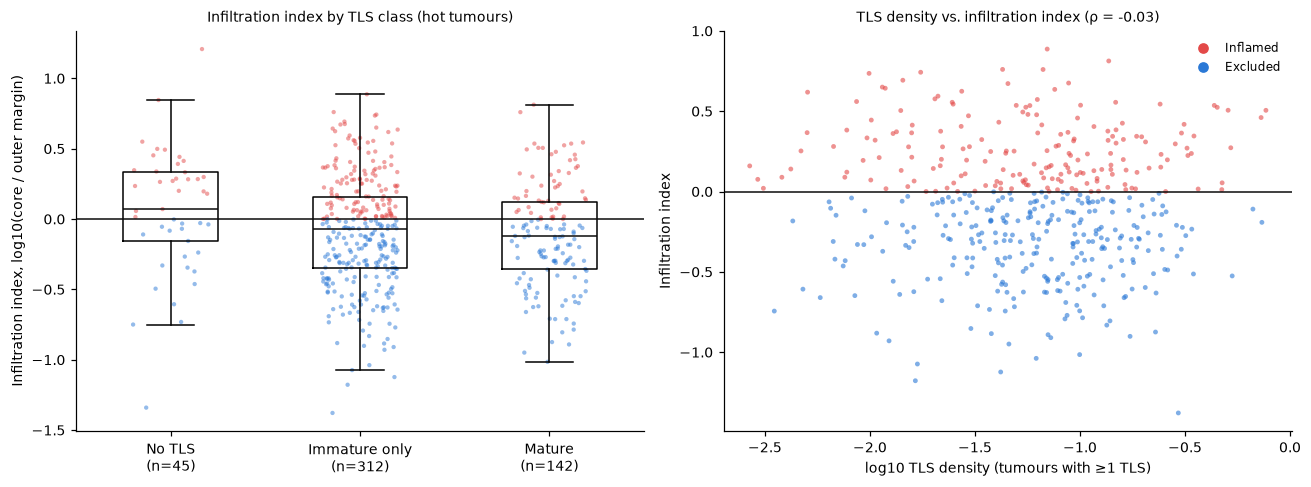

In [14]:
hot = df[df["spatial_phenotype"].isin(["Inflamed", "Excluded"])].copy()

print("TLS class by phenotype, hot tumours (row %):")
display((pd.crosstab(hot["spatial_phenotype"], hot["tls_group"], normalize="index") * 100)
        .reindex(columns=TLS_GROUPS).round(1))
for col, label in [("tls_density_total", "all"), (TLS_MATURE, "mature"), (TLS_IMMATURE, "immature")]:
    m = hot.loc[hot[col] > 0, [col, "spatial_index_wtr"]].dropna()
    print(f"{label} TLS density vs infiltration index (tumours with ≥1): "
          f"rho = {m[col].corr(m['spatial_index_wtr'], method='spearman'):.2f}, n = {len(m)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
data = [hot.loc[hot["tls_group"] == g, "spatial_index_wtr"].dropna() for g in TLS_GROUPS]
ax.boxplot(data, positions=range(len(TLS_GROUPS)), widths=0.5, showfliers=False, medianprops={"color": "#0b0b0b"})
rng = np.random.default_rng(0)
for i, values in enumerate(data):
    ax.scatter(i + rng.uniform(-0.2, 0.2, len(values)), values, s=8, alpha=0.5, linewidths=0,
               c=hot.loc[values.index, "spatial_phenotype"].map(PHENOTYPE_COLORS))
ax.axhline(0, color="#0b0b0b", lw=1)
ax.set_xticks(range(len(TLS_GROUPS)))
ax.set_xticklabels([f"{g}\n(n={len(v)})" for g, v in zip(TLS_GROUPS, data)])
ax.set_ylabel("Infiltration index, log10(core / outer margin)")
ax.set_title("Infiltration index by TLS class (hot tumours)", fontsize=9)

ax = axes[1]
m = hot[hot["tls_density_total"] > 0]
ax.scatter(np.log10(m["tls_density_total"]), m["spatial_index_wtr"], s=10, alpha=0.6, linewidths=0,
           c=m["spatial_phenotype"].map(PHENOTYPE_COLORS))
ax.axhline(0, color="#0b0b0b", lw=1)
rho = m["tls_density_total"].corr(m["spatial_index_wtr"], method="spearman")
ax.set_xlabel("log10 TLS density (tumours with ≥1 TLS)")
ax.set_ylabel("Infiltration index")
ax.set_title(f"TLS density vs. infiltration index (ρ = {rho:.2f})", fontsize=9)
ax.legend(handles=[Line2D([0], [0], marker="o", lw=0, color=c, label=k) for k, c in PHENOTYPE_COLORS.items()],
          frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIGS / "fig5_tls_vs_phenotype.png", bbox_inches="tight")
plt.show()

**Observations (breast)**
- Among hot tumours, the infiltration index barely differs between TLS classes, and TLS density is unrelated to it (ρ ≈ 0). TLS presence and the inflamed/excluded pattern behave as largely independent features.

In [15]:
hot["phenotype_binary"] = (hot["spatial_phenotype"] == "Inflamed").astype(float)
rows = []
for outcome in [v for v in TA["robustness_outcomes"] if v in hot.columns]:
    hot[f"{outcome}_z"] = zscore(hot[outcome])
    for spec, cont in [(f"Main ({SUBTYPE_LABEL} + purity)", [PURITY]),
                       ("+ mature TLS presence + immature TLS density", [PURITY, TLS_MATURE_PRESENT, TLS_IMMATURE])]:
        rows.append({"outcome": outcome, "specification": spec,
                     **fit_effect(hot, f"{outcome}_z", exposure="phenotype_binary", categorical=[SUBTYPE],
                                  continuous=cont)})
robustness = pd.DataFrame(rows)
if len(robustness):
    robustness.to_csv(OUT_DIR / "phenotype_robustness_to_tls.csv", index=False)
    display(robustness[["outcome", "specification", "effect", "ci_lower", "ci_upper", "p_value", "n"]].round(3))

,outcome,specification,effect,ci_lower,ci_upper,p_value,n
0,expr_COL10A1,Main (PAM50 subtype + purity),-0.311,-0.480,-0.143,0.0,473
1,expr_COL10A1,+ mature TLS presence + immature TLS density,-0.302,-0.471,-0.133,0.0,473


**Reading the robustness check:** the effect is the outcome difference, inflamed − excluded, in SD units (negative = higher in excluded). If it stays similar after adding the TLS covariates, the phenotype result is not explained by TLS.

**Limitation:** TLS location (core vs margin) is not available in the public OpenTME tables and would require the full Atlas H&E-TME outputs.

### 8.1 Mutation type of selected genes by TLS class

For the genes listed in `mutation_detail_genes` (breast: KMT2C), mutations are classified as truncating (likely loss of function) or missense / in-frame, from the filtered MC3 mutations saved in notebook 02.

In [16]:
maf_ns = pd.read_parquet(P["tcga_mutations"])
TRUNCATING = set(TA["truncating_classes"])
for GENE in TA["mutation_detail_genes"]:
    gene_muts = maf_ns[maf_ns["Hugo_Symbol"] == GENE].assign(patient=lambda m: m["Tumor_Sample_Barcode"].str[:12])
    print(f"{GENE}: {len(gene_muts)} mutations in {gene_muts['patient'].nunique()} patients")
    display(gene_muts["Variant_Classification"].value_counts())

    # One class per patient: truncating if any of its mutations is truncating
    per_patient = (gene_muts.groupby("patient")["Variant_Classification"]
                   .apply(lambda v: "Truncating" if set(v) & TRUNCATING else "Missense / in-frame"))
    display(per_patient.value_counts())
    display(gene_muts["HGVSp_Short"].value_counts().head(10))      # recurrent protein changes (hotspots)

    df[f"{GENE}_class"] = df["patient"].map(per_patient).fillna("Not mutated")
    df.loc[df["mut_profiled"] != 1, f"{GENE}_class"] = np.nan
    display(pd.crosstab(df["tls_group"], df[f"{GENE}_class"], normalize="index").mul(100).round(1).reindex(TLS_GROUPS))

KMT2C: 100 mutations in 83 patients


Variant_Classification
Missense_Mutation    37
Nonsense_Mutation    29
Frame_Shift_Del      20
Frame_Shift_Ins      10
Splice_Site           3
In_Frame_Del          1
Name: count, dtype: int64

Variant_Classification
Truncating             57
Missense / in-frame    26
Name: count, dtype: int64

HGVSp_Short
p.R4478*         2
p.Q1478*         2
p.S1334C         1
p.E2838K         1
p.S2123*         1
p.L1793F         1
p.W430C          1
p.S4081Ifs*12    1
p.L145*          1
p.P2437Tfs*8     1
Name: count, dtype: int64

KMT2C_class,Missense / in-frame,Not mutated,Truncating
tls_group,,,
No TLS,5.7,84.8,9.5
Immature only,2.2,91.7,6.1
Mature,2.1,95.4,2.6


**Observations (breast)**
- KMT2C mutations are mostly truncating with no hotspots (loss-of-function pattern), and their frequency decreases from No TLS to Mature tumours, driven by truncating variants.
- Association only; KMT2C mutations are enriched in luminal tumours.